# 06. 강건성 점검

**목적:** 05번의 핵심 결론이 **가정을 바꿔도 유지되는지** 확인한다.
- **강건성(robustness)**: 가정이나 숫자를 조금 바꿔도 결론이 흔들리지 않는 성질. 강건하지 않은 결론은 "그 가정에서만" 맞는 결론이다.

**점검할 핵심 결론 (Circle 수준 발행사, r* 3.6%)**

| | 결론 | 05번 메인 결과 |
|---|---|---|
| ① | 무헤지는 손실확률 5%를 넘는다 | 16.5% |
| ② | 최적 헤지 비율 h는 100%가 아니라 회사 몫(1 − s = 37.5%) 근처다 | h 37.5% |
| ③ | 3년 만기가 1년 롤링보다 손실확률이 낮다 | 0% vs 12.7% (K 4.1%·h 37.5%) |
| ④ | 최적 행사가 K는 손익분기 r* 이상이다 | K 4.1% = r* + 0.5 |

**점검 순서**
1. 시뮬레이션 오차: 신뢰구간, 난수 시드 5번 반복
2. 금리 모형 파라미터(a, σ)의 불확실성
3. 가정 변경 7가지 (Circle 수준만, 하나씩 따로)
4. 결론 ①~④ 유지 여부 ○/× 표
5. 부록: 1차 설정과 바꾼 이유

## 0. 준비
이 셀이 하는 일: 도구를 불러온다. 05번의 계산을 함수로 묶어 둔 `src/issuer_sim.py`를 쓴다(여러 설정을 반복해서 돌리기 위해).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import chi2

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"
sys.path.append(str(PROJECT))

from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE
from src.issuer_sim import (load_market, load_issuer, simulate_rates, evaluate_strategies,
                            pick_optimal, wilson_interval)
setup_plot_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

### 메인 설정 다시 만들기
이 셀이 하는 일: 05번과 같은 입력(곡선, C·s, 세 규모)을 준비하고, 메인 설정으로 다시 계산해 **05번 결과와 똑같이 나오는지** 확인한다.

In [2]:
market = load_market()
C, S = load_issuer()
RSTAR = {"신규 진입": 4.5, "Circle 수준": 3.6, "대형": 2.5}
R = {size: C / ((1 - S) * rstar / 100) for size, rstar in RSTAR.items()}
A, SIGMA, N_PATHS = 0.093, 0.64, 10_000
CIRCLE = "Circle 수준"

main_paths = simulate_rates(market, A, SIGMA, n_paths=N_PATHS, seed=42)
main_res, main_flags = {}, {}
for size in RSTAR:
    main_res[size], main_flags[size] = evaluate_strategies(main_paths, market, R[size], C, S, RSTAR[size], A, SIGMA)

best = pick_optimal(main_res[CIRCLE])
unhedged = main_res[CIRCLE].set_index("전략").loc["무헤지", "손실확률(%)"]
print(f"Circle 수준 무헤지 {unhedged:.2f}% | 최적 {best['전략']} → 손실확률 {best['손실확률(%)']:.2f}%, "
      f"비용 {best['총 헤지 비용(백만$)']:.1f}백만 달러   (05번: 16.53%, K 4.1% h37.5 3년, 0.00%, 88.2)")

Circle 수준 무헤지 16.53% | 최적 K r*+0.5 (4.10%) h37.5 3년 → 손실확률 0.00%, 비용 88.2백만 달러   (05번: 16.53%, K 4.1% h37.5 3년, 0.00%, 88.2)


## 1. 시뮬레이션 오차

경로 1만 개로 계산한 손실확률도 **표본에서 나온 추정값**이라 오차가 있다. 경로를 다시 뽑으면 조금 다른 값이 나온다.

### 1-1. 95% 신뢰구간
- 손실확률 p는 "1만 번 중 몇 번 적자가 났나"라서, 동전 던지기와 같은 방식으로 오차를 계산할 수 있다(이항분포).
- **Wilson 구간**: 비율의 신뢰구간을 구하는 방법. 0% 근처에서도 음수가 나오지 않아 여기에 맞다.
- **롤링 vs 3년 차이**: 같은 경로에서 계산했으므로, 경로마다 (롤링 적자 여부 − 3년 적자 여부)의 평균과 그 표준오차로 차이의 신뢰구간을 구한다. 0을 포함하지 않으면 차이가 우연이 아니다.

이 셀이 하는 일: 규모별 무헤지, Circle 최적 전략, 같은 K·h의 롤링과 3년 손실확률에 95% 신뢰구간을 붙인다.

In [3]:
def ci_row(flag):
    p = flag.mean()
    lo, hi = wilson_interval(p, len(flag))
    return {"손실확률(%)": p * 100, "95% 하한(%)": lo * 100, "95% 상한(%)": hi * 100}

rows = {f"{size} 무헤지": ci_row(main_flags[size]["무헤지"]) for size in RSTAR}
roll_name = best["전략"].replace("3년", "1년 롤링")
rows[f"Circle 최적: {best['전략']}"] = ci_row(main_flags[CIRCLE][best["전략"]])
rows[f"Circle 같은 K·h: {roll_name}"] = ci_row(main_flags[CIRCLE][roll_name])

diff = main_flags[CIRCLE][roll_name].astype(float) - main_flags[CIRCLE][best["전략"]].astype(float)
d_mean, d_se = diff.mean(), diff.std(ddof=1) / np.sqrt(len(diff))
rows["차이: 롤링 − 3년"] = {"손실확률(%)": d_mean * 100, "95% 하한(%)": (d_mean - 1.96 * d_se) * 100,
                        "95% 상한(%)": (d_mean + 1.96 * d_se) * 100}
pd.DataFrame(rows).T

,손실확률(%),95% 하한(%),95% 상한(%)
신규 진입 무헤지,90.190,89.591,90.758
Circle 수준 무헤지,16.530,15.815,17.271
대형 무헤지,0.790,0.634,0.983
Circle 최적: K r*+0.5 (4.10%) h37.5 3년,0.000,0.000,0.038
Circle 같은 K·h: K r*+0.5 (4.10%) h37.5 1년 롤링,12.730,12.091,13.398
차이: 롤링 − 3년,12.730,12.077,13.383


**읽는 법**
- **Circle 수준 무헤지 16.5%**의 95% 신뢰구간은 약 15.8~17.3%다. 5%보다 한참 위라서, 결론 ①은 시뮬레이션 오차 때문에 바뀔 수 없다.
- **대형 무헤지 0.8%**(0.6~1.0%)도 5%와 거리가 멀다.
- **Circle 최적 전략 0%**: 1만 경로 중 적자가 한 번도 없었다. 신뢰구간 상한도 약 0.04%다.
- **롤링 − 3년 차이**는 약 12.7%p이고, 95% 신뢰구간(12.1~13.4%p)이 0과 멀다. 같은 경로에서 비교했으므로 이 차이는 우연이 아니다(결론 ③).

### 1-2. 난수 시드를 바꿔 5번 반복
- **난수 시드**: 무작위 숫자를 뽑는 출발점. 시드를 바꾸면 완전히 다른 경로 1만 개가 나온다.

이 셀이 하는 일: 시드 1~5로 경로를 새로 뽑아, 규모별 무헤지 손실확률과 최적 전략이 바뀌는지 본다.

In [4]:
seed_rows = []
for seed in range(1, 6):
    paths_seed = simulate_rates(market, A, SIGMA, n_paths=N_PATHS, seed=seed)
    for size in RSTAR:
        res_seed, _ = evaluate_strategies(paths_seed, market, R[size], C, S, RSTAR[size], A, SIGMA)
        opt = pick_optimal(res_seed)
        seed_rows.append({
            "시드": seed, "규모": size,
            "무헤지(%)": res_seed.set_index("전략").loc["무헤지", "손실확률(%)"],
            "최적 전략": opt["전략"] if opt is not None else "없음",
            "최적 손실확률(%)": opt["손실확률(%)"] if opt is not None else np.nan,
        })
seeds = pd.DataFrame(seed_rows)
seeds.pivot(index="시드", columns="규모", values=["무헤지(%)", "최적 전략"]).reindex(columns=list(RSTAR), level=1)

무헤지(%)                 최적 전략                                
규모  신규 진입 Circle 수준    대형 신규 진입                  Circle 수준   대형
시드                                                             
1  90.050    17.690 0.770    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지
2  90.230    17.000 0.790    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지
3  89.830    17.250 0.670    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지
4  89.760    16.620 0.550    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지
5  89.960    16.630 0.670    없음  K r*+0.5 (4.10%) h37.5 3년  무헤지

**읽는 법**: 시드를 바꿔도 Circle 수준 무헤지는 약 16.6~17.7%, 최적 전략은 **5번 모두 K 4.1%·h 37.5%·3년**이다. 신규 진입은 5번 모두 "없음", 대형은 5번 모두 무헤지(0.55~0.79%)다. 시뮬레이션 오차로 최적 정책이 바뀌지 않는다.

## 2. 금리 모형 파라미터의 불확실성

03번에서 a(평균회귀 속도)와 σ(변동성)를 **하나의 숫자**로 추정했지만, 이것도 데이터에서 나온 추정값이라 오차가 있다.

- **a**: AR(1) 회귀 r(t+1) = c + φ·r(t) 의 φ로 계산한다(a = −ln φ ÷ (1/12)). φ의 신뢰구간 양 끝을 a로 바꾸면 a의 신뢰구간이 된다. φ가 1에 가까울수록 a는 0에 가깝다.
- **σ**: 잔차의 분산이 카이제곱분포를 따른다고 보고 신뢰구간을 구한다.
- 표준오차는 두 가지로 본다: 보통 OLS, 그리고 02번에서 쓴 **Newey-West(HAC)**(잔차가 서로 이어지거나 크기가 들쭉날쭉해도 맞는 방법).

이 셀이 하는 일: 03번과 같은 월평균 기준금리(2000-01 ~ 2026-09)로 AR(1)을 다시 돌려, φ·a·σ의 추정값, 표준오차, 95% 신뢰구간을 계산한다.

In [5]:
rates = pd.read_parquet(PROC_DIR / "rates.parquet")
r_monthly = rates["base_rate"].resample("ME").mean().loc["2000":"2026-09"]
y, x = r_monthly.iloc[1:].to_numpy(), r_monthly.iloc[:-1].to_numpy()
DT = 1 / 12

param_rows = {}
for label, fit_kw in [("보통 OLS", {}), ("Newey-West (시차 6)", {"cov_type": "HAC", "cov_kwds": {"maxlags": 6}})]:
    res = sm.OLS(y, sm.add_constant(x)).fit(**fit_kw)
    phi, se_phi = res.params[1], res.bse[1]
    phi_lo, phi_hi = res.conf_int()[1]
    to_a = lambda p: -np.log(p) / DT
    param_rows[label] = {
        "φ": phi, "φ 표준오차": se_phi, "φ 95% 하한": phi_lo, "φ 95% 상한": phi_hi,
        "a": to_a(phi), "a 표준오차": se_phi / (phi * DT),                  # 델타법: 작은 변화의 비례 관계
        "a 95% 하한": to_a(phi_hi), "a 95% 상한": to_a(phi_lo),
    }
param_table = pd.DataFrame(param_rows).T

ols = sm.OLS(y, sm.add_constant(x)).fit()
phi, n = ols.params[1], len(y)
a_hat = -np.log(phi) / DT
resid_sd = ols.resid.std(ddof=2)
to_sigma = np.sqrt(2 * a_hat / (1 - phi ** 2))
sigma_lo = np.sqrt((n - 2) * resid_sd ** 2 / chi2.ppf(0.975, n - 2)) * to_sigma
sigma_hi = np.sqrt((n - 2) * resid_sd ** 2 / chi2.ppf(0.025, n - 2)) * to_sigma
A_LO, A_HI = param_table.loc["보통 OLS", ["a 95% 하한", "a 95% 상한"]]

print(f"σ = {resid_sd * to_sigma:.3f}, 95% 신뢰구간 {sigma_lo:.3f} ~ {sigma_hi:.3f}  "
      f"(잔차 초과첨도 {pd.Series(ols.resid).kurt():.1f}: 꼬리가 두꺼워 실제 불확실성은 이보다 클 수 있음)")
param_table

σ = 0.638, 95% 신뢰구간 0.592 ~ 0.691  (잔차 초과첨도 7.9: 꼬리가 두꺼워 실제 불확실성은 이보다 클 수 있음)


,φ,φ 표준오차,φ 95% 하한,φ 95% 상한,a,a 표준오차,a 95% 하한,a 95% 상한
보통 OLS,0.992,0.005,0.982,1.002,0.093,0.061,-0.027,0.214
Newey-West (시차 6),0.992,0.009,0.975,1.009,0.093,0.106,-0.113,0.302


**a의 신뢰구간이 0을 포함한다** (보통 OLS 약 −0.03 ~ 0.21, Newey-West는 더 넓다).

**무슨 뜻인가?**
- a = 0이면 금리에 **평균으로 돌아가는 힘이 없다.** 금리가 한번 내려가면 다시 올라올 이유 없이 그 근처를 떠돈다(**랜덤워크**: 술 취한 사람의 걸음처럼 매번 무작위로 움직이고 돌아올 곳이 없는 움직임).
- 26년치 데이터로도 "금리가 평균으로 돌아온다"는 것을 통계적으로 **확신할 수 없다**는 뜻이다. 금리는 아주 느리게 움직여서, 한 번 오르고 내리는 사이클이 5~10년씩 걸린다. 26년이면 그런 사이클을 몇 번밖에 못 본다.
- a의 하한이 **음수**라는 것은 금리가 평균에서 점점 멀어지는(폭발하는) 모형인데, 경제적으로 말이 되지 않는다. 그래서 3번 점검에서 a의 하한은 **0(랜덤워크)**으로 둔다.
- 발행사에게 a = 0은 **나쁜 쪽**이다. 금리가 내려가도 다시 올라온다는 보장이 없어서, 저금리가 오래 이어질 수 있다. 3-(d)에서 이 경우를 직접 확인한다.

**σ의 신뢰구간**(약 0.59 ~ 0.69)은 상대적으로 좁다. 다만 잔차 꼬리가 두꺼워서(급격한 인하 몇 번) 실제 불확실성은 이보다 크다. 그래서 3-(b)에서 σ를 절반(0.32)으로 크게 바꿔 본다.

## 3. 가정 변경 (Circle 수준만, 하나씩 따로)

| 설정 | 바꾼 것 | 나머지 |
|---|---|---|
| 메인 | — | 시장 일치 모형, a 0.093, σ 0.64, 거래비용 2bp, h 37.5·50·100% (전략 25개) |
| (a) 스트레스 세계 C | 금리가 장기 평균 **1.32%**로 끌려가는 Vasicek (현재 SOFR에서 시작). **플로어 가격은 시장 곡선 그대로** | 메인과 같음 |
| (b) σ 0.32 | 시나리오와 가격 모두 σ 0.32 (최근 3년) | |
| (c) 거래비용 0bp / 5bp | 연 거래비용 | |
| (d) a 하한 / 상한 | 시나리오와 가격 모두 a = 0(랜덤워크) / a = 신뢰구간 상한 | |
| (e) h 50·100%만 | 헤지 비율 후보에서 37.5%를 빼고 이전 세트(50·100%)만 → 전략 17개 | |

**결론 판단 기준**
- ①: 무헤지 손실확률 > 5% → ○
- ②: 최적 전략의 h < 100% → ○ (최적이 무헤지면 판단 대상 없음 "—")
- ③: 최적 전략의 K·h에서(최적이 무헤지면 메인 최적 조합 **K r* + 0.5·h 37.5%**에서) 3년 손실확률 < 1년 롤링 손실확률 → ○
- ④: 최적 전략의 K ≥ r* → ○ (최적이 무헤지면 "—")

이 셀이 하는 일: 설정 목록을 정의하고, 각 설정으로 Circle 수준의 25개(또는 17개) 전략을 계산한다.

In [6]:
SETTINGS = {
    "메인":                  dict(),
    "(a) 스트레스 세계 C":      dict(world="vasicek", b=1.32),
    "(b) σ 0.32":           dict(sigma=0.32),
    "(c) 거래비용 0bp":        dict(tc=0.0),
    "(c) 거래비용 5bp":        dict(tc=5.0),
    f"(d) a 하한 → 0":       dict(a=max(A_LO, 0.0)),
    f"(d) a 상한 {A_HI:.3f}": dict(a=A_HI),
    "(e) h 50·100%만":        dict(h=(0.5, 1.0)),                  # 이전 h 세트
}

setting_results = {}
for name, kw in SETTINGS.items():
    a, sigma = kw.get("a", A), kw.get("sigma", SIGMA)
    paths = simulate_rates(market, a, sigma, n_paths=N_PATHS, seed=42, world=kw.get("world", "market"), b=kw.get("b"))
    res, _ = evaluate_strategies(paths, market, R[CIRCLE], C, S, RSTAR[CIRCLE], a, sigma,
                                 tc_bp=kw.get("tc", 2.0), hedge_ratios=kw.get("h"))
    setting_results[name] = res
print("계산한 설정:", list(setting_results))

계산한 설정: ['메인', '(a) 스트레스 세계 C', '(b) σ 0.32', '(c) 거래비용 0bp', '(c) 거래비용 5bp', '(d) a 하한 → 0', '(d) a 상한 0.214', '(e) h 50·100%만']


### 설정별 결과와 결론 ①~④
이 셀이 하는 일: 설정마다 무헤지 손실확률, 최적 전략, 롤링 vs 3년 비교를 정리하고 결론 ①~④를 ○/×/— 로 판정한다.

In [7]:
def judge(res):
    unh = res.set_index("전략").loc["무헤지", "손실확률(%)"]
    opt = pick_optimal(res)
    hedged_opt = opt is not None and opt["전략"] != "무헤지"
    # ③ 비교할 K·h: 헤지가 최적이면 그 조합, 아니면 메인 최적 조합(K r*+0.5, h 1 − s)
    off, h = (opt["K−r*"], opt["h"]) if hedged_opt else (0.5, round(1 - S, 3))
    pair = res[(res["K−r*"] == off) & (res["h"] == h)].set_index("만기")["손실확률(%)"]
    return {
        "무헤지(%)": unh,
        "최적 전략": opt["전략"] if opt is not None else "없음",
        "최적 손실확률(%)": opt["손실확률(%)"] if opt is not None else np.nan,
        "최적 비용(백만$)": opt["총 헤지 비용(백만$)"] if opt is not None else np.nan,
        "비교 K·h": f"K r*{off:+.1f}, h {h * 100:g}%",
        "롤링(%)": pair["1년 롤링"], "3년(%)": pair["3년"],
        "①": "○" if unh > 5 else "×",
        "②": ("○" if opt["h"] < 1.0 else "×") if hedged_opt else "—",
        "③": "○" if pair["3년"] < pair["1년 롤링"] else "×",
        "④": ("○" if opt["K−r*"] >= 0 else "×") if hedged_opt else "—",
    }

verdict = pd.DataFrame({name: judge(res) for name, res in setting_results.items()}).T
verdict

,무헤지(%),최적 전략,최적 손실확률(%),최적 비용(백만$),비교 K·h,롤링(%),3년(%),①,②,③,④
메인,16.530,K r*+0.5 (4.10%) h37.5 3년,0.000,88.201,"K r*+0.5, h 37.5%",12.730,0.000,○,○,○,○
(a) 스트레스 세계 C,76.060,K r*+0.5 (4.10%) h37.5 3년,0.000,88.201,"K r*+0.5, h 37.5%",68.180,0.000,○,○,○,○
(b) σ 0.32,1.070,무헤지,1.070,0.000,"K r*+0.5, h 37.5%",0.520,0.000,×,—,○,—
(c) 거래비용 0bp,16.530,K r*+0.5 (4.10%) h37.5 3년,0.000,72.171,"K r*+0.5, h 37.5%",12.000,0.000,○,○,○,○
(c) 거래비용 5bp,16.530,K r*+0.5 (4.10%) h37.5 3년,0.000,112.246,"K r*+0.5, h 37.5%",13.870,0.000,○,○,○,○
(d) a 하한 → 0,19.150,K r*+0.5 (4.10%) h37.5 3년,0.000,100.300,"K r*+0.5, h 37.5%",15.910,0.000,○,○,○,○
(d) a 상한 0.214,13.640,K r*+0.5 (4.10%) h37.5 3년,0.000,75.812,"K r*+0.5, h 37.5%",8.980,0.000,○,○,○,○
(e) h 50·100%만,16.530,K r*+0.5 (4.10%) h50 3년,0.000,117.601,"K r*+0.5, h 50%",12.970,0.000,○,○,○,○


### 결론 유지 표
이 셀이 하는 일: 결론 ①~④의 ○/× 만 모아 한눈에 보는 표와, 설정마다 네 결론이 모두 유지되는지를 정리한다. 판정 결과는 `data/processed/robustness_verdict.csv`로 저장한다.

In [8]:
marks = verdict[["①", "②", "③", "④"]].copy()
marks["네 결론 모두 유지"] = marks.apply(lambda row: "○" if (row == "○").all() else "×", axis=1)
n_hold, n_all = (marks["네 결론 모두 유지"] == "○").sum(), len(marks)
print(f"네 가지 결론은 {n_all}개 설정 중 {n_hold}개에서 모두 유지된다.")
verdict.to_csv(PROC_DIR / "robustness_verdict.csv")   # 07번(최종 그래프)에서 사용
marks

네 가지 결론은 8개 설정 중 7개에서 모두 유지된다.


,①,②,③,④,네 결론 모두 유지
메인,○,○,○,○,○
(a) 스트레스 세계 C,○,○,○,○,○
(b) σ 0.32,×,—,○,—,×
(c) 거래비용 0bp,○,○,○,○,○
(c) 거래비용 5bp,○,○,○,○,○
(d) a 하한 → 0,○,○,○,○,○
(d) a 상한 0.214,○,○,○,○,○
(e) h 50·100%만,○,○,○,○,○


### 그림: 설정별 무헤지 vs 최적 전략 손실확률
이 셀이 하는 일: 설정마다 무헤지(회색)와 최적 전략(파랑) 손실확률을 막대로 그리고, 5% 기준선을 긋는다.

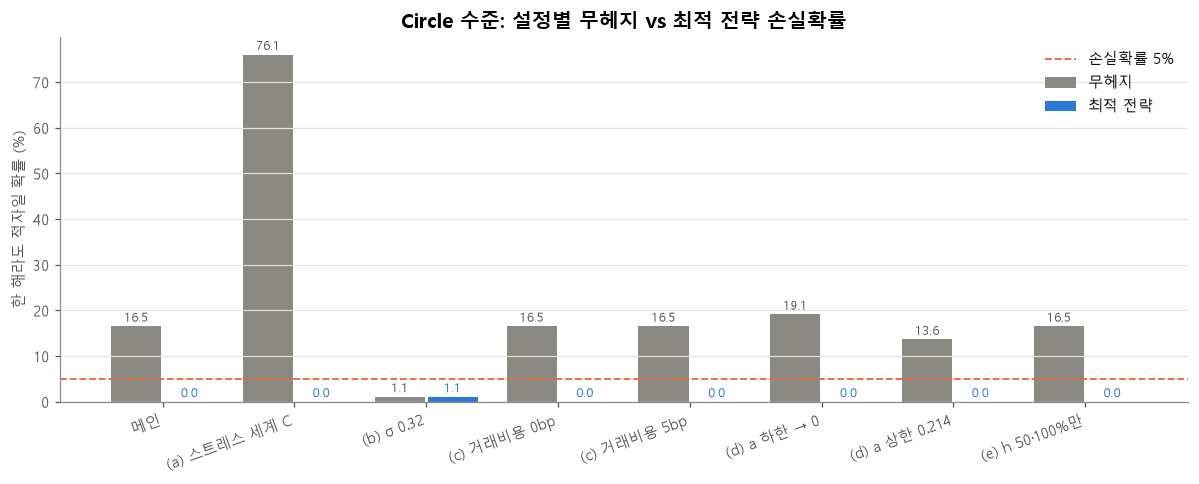

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
xpos = np.arange(len(verdict))
ax.bar(xpos - 0.2, verdict["무헤지(%)"].astype(float), width=0.38, color=MUTED, label="무헤지")
ax.bar(xpos + 0.2, verdict["최적 손실확률(%)"].astype(float), width=0.38, color=COLORS[0], label="최적 전략")
ax.axhline(5, color=COLORS[1], linestyle="--", linewidth=1.2, label="손실확률 5%")
for xi, v in zip(xpos, verdict["무헤지(%)"].astype(float)):
    ax.text(xi - 0.2, v + 1, f"{v:.1f}", ha="center", fontsize=8, color=TEXT_SUB)
for xi, v in zip(xpos, verdict["최적 손실확률(%)"].astype(float)):   # 0%여도 보이게 숫자 표시
    ax.text(xi + 0.2, v + 1, f"{v:.1f}", ha="center", fontsize=8, color=COLORS[0])
ax.set_xticks(xpos)
ax.set_xticklabels(verdict.index, rotation=20, ha="right")
ax.grid(axis="x", visible=False)
ax.set_title("Circle 수준: 설정별 무헤지 vs 최적 전략 손실확률")
ax.set_ylabel("한 해라도 적자일 확률 (%)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "7_robustness.png", dpi=200)
plt.show()

### 뒤집히는 설정: (b) σ 0.32
- 금리의 흔들림을 절반(최근 3년 수준)으로 줄이면, 3년 동안 금리가 Circle의 손익분기점(기준금리 3.75%) 아래로 내려가는 경로가 거의 없어진다. 지금 선도금리가 4.0~4.8%로 손익분기점보다 높기 때문이다.
- 그래서 **무헤지 손실확률이 1.1%**로 5% 아래가 되고(① ×), 헤지할 이유가 없어 ②·④는 판단할 대상이 없다(—).
- ③(3년 만기가 롤링보다 나음)은 여기서도 유지된다(0% vs 0.5%).
- **의미**: 결론 ①("Circle 수준도 헤지가 필요하다")은 **금리 변동성이 장기 평균(0.64) 수준**이라는 가정에 기대고 있다. 최근 3년처럼 조용한 시기가 계속된다면 헤지가 필요 없다. 반대로 **"헤지를 한다면 어떻게"에 대한 결론(②·③·④)은 이 설정에서도 틀리지 않는다.**

### 결론이 유지되지만 눈여겨볼 설정
- **(a) 스트레스 세계 C**: 금리가 1.32%로 끌려가면 무헤지 손실확률이 **76%**로 뛴다. 그래도 최적 전략과 비용은 메인과 같다. 플로어는 **시장 가격**(선도금리 기준)으로 사므로, 시장이 예상하지 못한 하락을 3년 만기가 그대로 막아 준다. 반면 롤링은 68%로 거의 효과가 없다. 금리가 내려간 뒤 다시 사면 이미 비싸졌기 때문이다.
- **(d) a = 0 (랜덤워크)**: 무헤지 19.2%로 조금 나빠지고, 같은 플로어의 가격(등가 σ)이 올라 비용이 약 1.00억 달러로 늘지만 결론은 같다.
- **(e) h 50·100%만 (이전 세트)**: 37.5%가 없으면 최적 전략이 h 50%가 되고 비용이 약 1.18억 달러로 **약 33% 늘어난다**(0.88억 → 1.18억). 손실확률은 둘 다 0%다. 회사 몫(1 − s)만큼만 사는 것이 같은 보호를 가장 싸게 얻는 방법이라는 결론 ②를 직접 확인해 준다.

## 4. 요약

**네 가지 결론은 8개 설정 중 7개에서 모두 유지된다.** 뒤집히는 것은 σ를 절반(0.32)으로 줄인 설정 하나이고, 그때도 결론 ①(헤지가 필요하다)만 바뀌며 ③은 유지된다.

| 점검 | 결과 |
|---|---|
| 시뮬레이션 오차 | 무헤지 16.5% (15.8~17.3%), 롤링 − 3년 차이 12.7%p (12.1~13.4%p). 시드 5개 모두 같은 최적 전략(K 4.1%·h 37.5%·3년) |
| 파라미터 불확실성 | a의 95% 신뢰구간이 0을 포함(−0.03~0.21): 평균회귀를 통계적으로 확신할 수 없다. a = 0으로 바꿔도 결론 유지 |
| 가정 변경 7개 | σ 0.32에서만 ① 뒤집힘. 세계 C, 거래비용 0·5bp, a 하한·상한, h 이전 세트(50·100%)에서 ①~④ 모두 유지 |

- 가장 강한 결론은 **③ 3년 만기 > 1년 롤링**이다. 8개 설정 모두에서 유지되고, 금리가 크게 내려가는 세계 C에서 차이가 가장 크다(0% vs 68%).
- 가장 약한 결론은 **① 무헤지는 5%를 넘는다**이다. 금리 변동성 가정에 따라 달라진다.

## 부록: 분석 설정의 변경 이력 (발제안 부록용)

### 1차 설정과 결과

| 항목 | 1차 설정 |
|---|---|
| 발행량 성장률 | 최근 24개월 평균 (월 0.0219, 연 약 30%) — 3년간 R이 2.2배 |
| 규모 | 손익분기 금리 r* 기준 소형 3.9% / 중형 2.5% / 대형 1.5% (R 658 / 1,026 / 1,710억 달러) |
| 행사가 | 모든 규모에 고정 2.0, 2.5, 3.0, 3.5% |
| 평가 지표 | 3년 누적 손익(할인 없이 합산) < 0 인 경로 비율 |
| 준비금 수익률 | max(r, 0) (기준금리와 같다고 봄) |
| 공통 | 시장 일치 금리 모형(a 0.093, σ 0.64), 국채 곡선 −18bp 보정 + PCHIP, 바슐리에 + 등가 σ, 거래비용 연 2bp, h 50·100%, 1년 롤링·3년 |

**1차 결과**
- 세 규모 모두 무헤지 손실확률이 0.03% 이하 → 17개 전략 모두 5% 기준 통과 → **최적 정책 = 모든 규모에서 무헤지**.
- 헤지 비용의 대부분이 거래비용이었고, 효율적 투자선이 사실상 무헤지 한 점으로 줄어 비교가 성립하지 않았다.
- 진단: 성장률을 0으로 두면 소형의 무헤지 손실확률이 0.03% → 11.8%로 뛰었다. 그래도 가장 좋은 전략(K 3.5%·h 100%·3년)이 10.6%로 5%에 닿지 못했다. 행사가가 소형의 r*보다 낮았기 때문이다.

### 무엇을 왜 바꿨나

| 항목 | 1차 | 최종 | 바꾼 이유 |
|---|---|---|---|
| 성장률 | 연 30% | **0** (연 30%는 비교용) | 손실확률은 성장이 멈춘 경우에도 버티는지를 봐야 한다. 최근 24개월은 금리 인하기와 GENIUS법이 겹친 특수 시기였다. 1차에서는 성장 가정이 금리 위험을 가렸다(소형 0.03% vs g = 0이면 11.8%) |
| 규모 정의 | r* 3.9 / 2.5 / 1.5% | **신규 진입 4.5 / Circle 수준 3.6 / 대형 2.5%** | 실제 Circle의 r*(3.6%)를 기준점으로 삼고, 선도금리보다 손익분기점이 높은 신규 진입 발행사를 넣어 규모 효과를 보이기 위해 |
| 행사가 | 고정 2.0~3.5% | **규모별 r* − 1, − 0.5, r*, r* + 0.5%** | 고정 행사가가 손익분기점보다 낮으면, 손익분기 근처의 금리 하락을 막을 수 없다. 행사가는 각 발행사의 손익분기점을 기준으로 정해야 비교가 공정하다 |
| 평가 지표 | 3년 누적 적자 | **한 해라도 연간 적자** (누적은 참고) | 누적 손익은 초반 이익이 뒤의 손실을 덮어 위험을 작게 보이게 한다(Circle 수준: 누적 7.2% vs 한 해라도 16.5%). 실제 회사는 한 해의 적자도 신용·규제상 부담이 된다 |
| 준비금 수익률 | max(r, 0) | **max(r, 0) − 0.15%p** | Circle 공시로 계산한 실제 준비금 수익률이 9개 분기 모두 기준금리보다 0.1~0.2%p 낮았다 |
| 헤지 비율 후보 | 50, 100% | **1 − s(37.5%), 50, 100%** (전략 25개) | 강건성 점검에서 발행사 몫(1 − s)만큼의 명목이 같은 보호(손실확률 0%)를 약 25% 싸게 주는 것을 확인했다. 발행사는 준비금 이자의 37.5%만 가지므로 그만큼만 헤지하면 된다 |

### 참고: 05번 이전 단계에서 바꾼 것
- **금리 시나리오**: 과거 데이터로 추정한 Vasicek(장기 평균 b = FOMC 3.2%, 스트레스 1.32%) → **시장 일치 모형**(경로 평균 = 선도금리). 시나리오와 플로어 가격의 기준을 일치시키기 위해서다. Vasicek 세계는 부록(세계 B·C)으로 남겼다.
- **수익률곡선**: 국채 곡선 그대로 → **1개월 국채 − SOFR 차이(18bp)를 빼는 보정 + PCHIP 보간**. 국채가 SOFR보다 높아 플로어가 싸게 나오는 문제와, 직선 보간 때문에 2년 지점에서 선도금리가 꺾이는 문제를 고쳤다.
- **플로어 가격의 σ**: 0.64 고정 → **등가 σ**(평균회귀 반영). 시뮬레이션과 가격이 같은 금리 퍼짐을 쓰게 하기 위해서다. σ 0.64 고정 가격(31~80% 더 비쌈)은 부록으로 남겼다.
- **발행량과 금리의 관계**: 회귀 추정값 b1 = −0.039(p = 0.08)는 신뢰구간이 0을 포함한다. 그래서 가장 보수적인 **b1 = 0**(금리가 내려도 발행량이 늘지 않음)을 메인으로 썼다.